# Follower pressure

A follower pressure stays normal to the deformed mid-surface and acts on its
deformed area. This example computes, with `update_fext_follower` and
`update_KCfollower`:

1. the large deflection of a cantilever plate under a dead and a follower
   pressure, with both truncations of the area vector, against reference
   values of the plate_clpt_donnell model of panels;
2. the tangent stiffness matrix with the load stiffness matrix against
   central finite differences of the residual;
3. the asymmetry of the load stiffness matrix for several boundary
   conditions and pressures.

The same models are checked in `tests/test_follower_pressure.py`.

## Theory

A pressure of a gas or a liquid stays normal to the deformed plate and acts
on its deformed area, as opposed to a dead pressure, which keeps the
direction $z$ and the undeformed area; its force vector depends on the
displacements, and its derivative, the load stiffness matrix, enters the
tangent stiffness matrix [1, 2]. With $\boldsymbol{X} = \boldsymbol{X}_0 +
\boldsymbol{u}$ the deformed position of the mid-surface, the virtual work
of the pressure $p$, given per unit undeformed area, is

$$
\delta W_p = \int_A p \, \boldsymbol{a} \cdot \delta\boldsymbol{u} \, dA,
\qquad \boldsymbol{a} = \boldsymbol{X}_{,x} \times \boldsymbol{X}_{,y}
$$

The area vector splits by orders in the displacement gradients,
$\boldsymbol{a} = \boldsymbol{a}_0 + \boldsymbol{a}_1 + \boldsymbol{a}_2$,

$$
\boldsymbol{a}_0 = \begin{Bmatrix} 0 \\ 0 \\ 1 \end{Bmatrix}, \qquad
\boldsymbol{a}_1 = \begin{Bmatrix} -w_{,x} \\ -w_{,y} \\
u_{,x} + v_{,y} \end{Bmatrix}, \qquad
\boldsymbol{a}_2 = \begin{Bmatrix} v_{,x} w_{,y} - w_{,x} v_{,y} \\
w_{,x} u_{,y} - u_{,x} w_{,y} \\ u_{,x} v_{,y} - v_{,x} u_{,y} \end{Bmatrix}
$$

With the moderate rotations of the von Kármán strains, the first-order area
vector $\boldsymbol{a}_0 + \boldsymbol{a}_1$ (`quadratic=0`) is the
consistent truncation: the force vector is affine in the displacements and
the load stiffness matrix constant. `quadratic=1` keeps $\boldsymbol{a}_2$.
Discretised with the rows $\boldsymbol{S}^u$, $\boldsymbol{S}^v$,
$\boldsymbol{S}^w$ of the element, the force vector of
`update_fext_follower` and the load stiffness matrix of `update_KCfollower`
are

$$
\boldsymbol{F}_p = \int_A p \left( (\boldsymbol{S}^u)^\top a_x +
(\boldsymbol{S}^v)^\top a_y + (\boldsymbol{S}^w)^\top a_z \right) dA,
\qquad
\boldsymbol{K}_F = -\frac{\partial \boldsymbol{F}_p}{\partial
\boldsymbol{u}_e}
$$

At $\boldsymbol{u} = \boldsymbol{0}$,
$\boldsymbol{F}_p(\boldsymbol{0}) = \int_A p (\boldsymbol{S}^w)^\top dA$ is
the force vector of the dead pressure; `reference=0` gives
$\boldsymbol{F}_p(\boldsymbol{u}) - \boldsymbol{F}_p(\boldsymbol{0})$. The
residual of the nonlinear static analysis under the pressure $\lambda p$ and
its Jacobian are

$$
\boldsymbol{R}(\boldsymbol{u}) = \boldsymbol{F}_{int}(\boldsymbol{u}) -
\lambda \boldsymbol{F}_p(\boldsymbol{u}), \qquad
\boldsymbol{K}_T = \boldsymbol{K}_{C0} + \boldsymbol{K}_{CNL} +
\boldsymbol{K}_{GNL} + \boldsymbol{K}_G + \boldsymbol{K}_F
$$

In [1]:
%matplotlib inline
import numpy as np
from numpy import isclose
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve
from composites import isotropic_plate, laminated_plate

from bfscplate2d import (BFSCPlate2D, update_KC0, update_KCNL, update_KG,
        update_fint, update_fext_follower, update_KCfollower, DOF, DOUBLE,
        INT, KC0_SPARSE_SIZE, KCNL_SPARSE_SIZE, KG_SPARSE_SIZE,
        KCfollower_SPARSE_SIZE)
from bfscplate2d.quadrature import get_points_weights

## Mesh helper

A helper class builds a rectangular mesh of $n_x$ by $n_y$ nodes and
assembles the force vector of the follower pressure, the load stiffness
matrix $\boldsymbol{K}_F$, the internal forces $\boldsymbol{F}_{int}$ and
the tangent stiffness matrix without the load,
$\boldsymbol{K}_{C0} + \boldsymbol{K}_{CNL} + \boldsymbol{K}_{GNL} +
\boldsymbol{K}_G$. The method `pressure` gives the array `p` of each element
at its integration points. Six integration points per direction integrate
exactly the complete area vector with a pressure of degree 2. The default
laminate, $[30/-45/0/90]$, is unsymmetric and unbalanced, such that
$A_{16}$, $A_{26}$ and $\boldsymbol{B}$ are non-zero, and the default
pressure `p_function` varies over the plate; they are used in the checks of
the tangent and of the symmetry. `boundary_flags` constrains, along an edge,
a displacement and its derivative along the edge, and `asym` is the
asymmetry measure $\|\boldsymbol{K} - \boldsymbol{K}^\top\| /
\|\boldsymbol{K}\|$.

In [2]:
NINT = 6
TRUNCATIONS = [0, 1]

LAMINAPROP = (142.5e9, 142.5e9/20, 0.25, 0.5*142.5e9/20, 0.5*142.5e9/20,
              0.5*142.5e9/20)
LAMINATE = laminated_plate(stack=[30, -45, 0, 90], laminaprop=LAMINAPROP,
                           plyt=0.125e-3)

A, B = 0.3, 0.2


def p_function(x, y):
    """Non-uniform pressure, of degree 2"""
    return 1.e4*(1 + x/A - 2*y**2/B**2)


class Mesh(object):
    """Rectangular mesh of ``nx`` by ``ny`` nodes over ``a`` by ``b``, with
    the assembly of the vectors and matrices used below"""
    def __init__(self, nx=4, ny=3, a=A, b=B, lam=LAMINATE, nint=NINT):
        self.a, self.b = a, b
        self.points, self.weights = get_points_weights(nint=nint)
        xlin = np.linspace(0, a, nx)
        ylin = np.linspace(0, b, ny)
        xmesh, ymesh = np.meshgrid(xlin, ylin)
        ncoords = np.vstack((xmesh.T.flatten(), ymesh.T.flatten())).T
        self.x = ncoords[:, 0]
        self.y = ncoords[:, 1]
        nids_mesh = np.arange(nx*ny).reshape(nx, ny)
        n1s = nids_mesh[:-1, :-1].flatten()
        n2s = nids_mesh[1:, :-1].flatten()
        n3s = nids_mesh[1:, 1:].flatten()
        n4s = nids_mesh[:-1, 1:].flatten()
        self.N = DOF*nx*ny
        self.elements = []
        for k, (n1, n2, n3, n4) in enumerate(zip(n1s, n2s, n3s, n4s)):
            plate = BFSCPlate2D()
            plate.n1, plate.n2, plate.n3, plate.n4 = n1, n2, n3, n4
            plate.c1 = DOF*n1
            plate.c2 = DOF*n2
            plate.c3 = DOF*n3
            plate.c4 = DOF*n4
            plate.ABD = lam.ABD
            plate.lex = a/(nx - 1)
            plate.ley = b/(ny - 1)
            plate.init_k_KC0 = k*KC0_SPARSE_SIZE
            plate.init_k_KCNL = k*KCNL_SPARSE_SIZE
            plate.init_k_KG = k*KG_SPARSE_SIZE
            plate.init_k_KCfollower = k*KCfollower_SPARSE_SIZE
            self.elements.append(plate)
        self.h = lam.h

    def pressure(self, plate, func):
        """``p[i, j]`` at ``xi = points[i]``, ``eta = points[j]``"""
        x1, y1 = self.x[plate.n1], self.y[plate.n1]
        x = x1 + plate.lex*(self.points + 1)/2
        y = y1 + plate.ley*(self.points + 1)/2
        p = func(x[:, None], y[None, :])*np.ones((x.size, y.size))
        return np.ascontiguousarray(p, dtype=DOUBLE)

    def fext_follower(self, u, func, quadratic, reference=1):
        f = np.zeros(self.N, dtype=DOUBLE)
        for plate in self.elements:
            update_fext_follower(u, plate, self.points, self.weights,
                                 self.pressure(plate, func), f, quadratic,
                                 reference)
        return f

    def _matrix(self, size, call):
        n = size*len(self.elements)
        r = np.zeros(n, dtype=INT)
        c = np.zeros(n, dtype=INT)
        v = np.zeros(n, dtype=DOUBLE)
        for plate in self.elements:
            call(plate, r, c, v)
        return coo_matrix((v, (r, c)), shape=(self.N, self.N)).tocsc()

    def KCfollower(self, u, func, quadratic):
        return self._matrix(KCfollower_SPARSE_SIZE,
            lambda plate, r, c, v: update_KCfollower(u, plate, self.points,
                self.weights, self.pressure(plate, func), r, c, v,
                quadratic))

    def KC0(self):
        return self._matrix(KC0_SPARSE_SIZE,
            lambda plate, r, c, v: update_KC0(plate, self.points,
                self.weights, r, c, v))

    def KT(self, u):
        """K_C0 + K_CNL + K_GNL + K_G at u, without the load stiffness"""
        KCNL = self._matrix(KCNL_SPARSE_SIZE,
            lambda plate, r, c, v: update_KCNL(u, plate, self.points,
                self.weights, r, c, v))
        KG = self._matrix(KG_SPARSE_SIZE,
            lambda plate, r, c, v: update_KG(u, plate, self.points,
                self.weights, r, c, v))
        return self.KC0() + KCNL + KG

    def fint(self, u):
        f = np.zeros(self.N, dtype=DOUBLE)
        for plate in self.elements:
            update_fint(u, plate, self.points, self.weights, f)
        return f

    def random_state(self, rng, scale=1.):
        """In-plane displacements of the order of the thickness, deflections
        well above it, such that the nonlinear terms carry weight"""
        u = scale*self.h*rng.standard_normal(self.N)
        u[6::DOF] *= 20
        lmin = min(self.a, self.b)
        for i in (1, 2, 4, 5, 7, 8):
            u[i::DOF] *= 1/lmin
        u[7::DOF] *= 20
        u[8::DOF] *= 20
        u[9::DOF] *= 20/lmin**2
        return u


def boundary_flags(m, edges):
    """Constrained degrees of freedom: for each edge in ``edges``, a dict
    ``{'x1': 'w', ...}`` of the displacements set to zero along it, with
    their derivatives along the edge"""
    bk = np.zeros(m.N, dtype=bool)
    on = {'x1': isclose(m.x, 0), 'x2': isclose(m.x, m.a),
          'y1': isclose(m.y, 0), 'y2': isclose(m.y, m.b)}
    # value and derivative along the edge: y for the edges x = const
    along = {'x': {'u': (0, 2), 'v': (3, 5), 'w': (6, 8)},
             'y': {'u': (0, 1), 'v': (3, 4), 'w': (6, 7)}}
    for edge, fields in edges.items():
        for f in fields:
            for i in along[edge[0]][f]:
                bk[i::DOF] |= on[edge]
    return bk


def asym(K):
    """Asymmetry measure ||K - K^T||/||K|| (Frobenius norms)"""
    K = K.toarray()
    return np.linalg.norm(K - K.T)/np.linalg.norm(K)


## Large deflection of a cantilever plate

A square isotropic plate, $a = b = 0.3$ m, $h = 2$ mm, $E = 70$ GPa,
$\nu = 0.3$, meshed with 10 by 10 elements, is clamped at $x = 0$ ($u$,
$v$, $w$ and their derivatives along the edge, plus $w_{,x}$ and
$w_{,xy}$), the other edges free, under a uniform pressure $p = 2$ kPa
pushing along $+z$. The tip deflection reaches about 20 times the thickness,
$w/a \approx 0.13$. Because of the free edges the load stiffness matrix is
unsymmetric (see the last section):

In [3]:
E, nu, h = 70.e9, 0.3, 2.e-3
a = b = 0.3
nel = 10
m = Mesh(nx=nel + 1, ny=nel + 1, a=a, b=b,
         lam=isotropic_plate(thickness=h, E=E, nu=nu))
# clamped edge x = 0
bk = boundary_flags(m, {'x1': 'uvw'})
bk[7::DOF] |= isclose(m.x, 0)
bk[9::DOF] |= isclose(m.x, 0)
bu = ~bk
func = lambda x, y: 2.e3 + 0*x*y
# the middle of the free edge x = a
tip = np.where(isclose(m.x, a) & isclose(m.y, b/2))[0][0]

KF = m.KCfollower(np.zeros(m.N), func, 0)
print('unknown degrees of freedom', bu.sum())
print('asymmetry of K_F over the unknown dofs: %.3e' % asym(KF[bu, :][:, bu]))

unknown degrees of freedom 1122
asymmetry of K_F over the unknown dofs: 5.398e-01


The load factor $\lambda$ goes from 0 to 1 in five equal increments. At
each one, the full Newton-Raphson method corrects the unknown
displacements with $\Delta\boldsymbol{u} = -\boldsymbol{K}_T^{-1}
\boldsymbol{R}$ until the relative residual
$\|\boldsymbol{R}\| / \|\boldsymbol{F}\|$ over the unknown degrees of
freedom is below $10^{-9}$. Under the dead pressure the external force is
$\lambda \boldsymbol{F}_p(\boldsymbol{0})$ and the tangent has no load
stiffness; under the follower pressure it is
$\boldsymbol{F}_p(\boldsymbol{u})$ of the pressure $\lambda p$ and the
tangent includes $\boldsymbol{K}_F$ of $\lambda p$, unsymmetric, so the
linear systems are solved with the LU factorisation of `spsolve`:

In [4]:
increments = 5
tol = 1.e-9
LOADS = ('dead', 0, 1)
NAMES = {'dead': 'dead', 0: 'follower, quadratic=0',
         1: 'follower, quadratic=1'}
out = {}
paths = {}
histories = {}
for load in LOADS:
    u = np.zeros(m.N)
    paths[load] = [(0., 0., 0.)]
    histories[load] = []
    for lbd in np.linspace(0, 1, increments + 1)[1:]:
        pf = lambda x, y: lbd*func(x, y)
        history = []
        for count in range(30):
            if load == 'dead':
                F = m.fext_follower(0*u, pf, 0)
            else:
                F = m.fext_follower(u, pf, load)
            R = m.fint(u) - F
            history.append(np.linalg.norm(R[bu])/np.linalg.norm(F[bu]))
            if history[-1] < tol:
                break
            KT = m.KT(u)
            if load != 'dead':
                KT = KT + m.KCfollower(u, pf, load)
            u[bu] -= spsolve(KT[bu, :][:, bu].tocsc(), R[bu])
        else:
            print('not converged at lambda =', lbd)
        histories[load].append(history)
        paths[load].append((lbd, u[DOF*tip + 6]/h, u[DOF*tip]))
    out[load] = dict(w=u[DOF*tip + 6]/h, u=u[DOF*tip])
    print('%-22s iterations per increment: %s' % (NAMES[load],
          [len(hist) - 1 for hist in histories[load]]))

dead                   iterations per increment: [5, 5, 5, 5, 4]


follower, quadratic=0  iterations per increment: [5, 5, 5, 5, 4]


follower, quadratic=1  iterations per increment: [5, 5, 5, 5, 4]


No closed-form solution applies to the large deflection of a flat plate
under a follower pressure, so the reference values are those of the
plate_clpt_donnell model of panels, the same von Kármán strains and area
vector discretized with $m = n = 16$ Bardell functions [3] and
$20 \times 20$ Gauss points, solved with the Newton-Raphson method of
structsolve with 10 increments and `relTOL = 1e-11`. Refining from
$m = n = 12$ changes $w$ by $2 \times 10^{-4}$; the mesh of 10 by 10
elements used here is within $5 \times 10^{-4}$ of these values (20 by 20
elements: $5 \times 10^{-5}$), both converging from below. The values,
$w/h$ and $u$ at the middle of the free edge $(a, b/2)$, are those stored in
the tests as `PANELS`.

In [5]:
# reference values of the plate_clpt_donnell model of panels, w/h and u (m)
# at (a, b/2) of the cantilever
PANELS = {
    'dead': dict(w=20.05040761, u=-3.06710517e-03),
    0: dict(w=20.23571166, u=-3.12566486e-03),
    1: dict(w=20.23571209, u=-3.12566500e-03),
}

print('%-22s %12s %12s %10s  %14s %14s %10s' % ('pressure', 'w/h', 'panels',
      'rel. diff', 'u (m)', 'panels', 'rel. diff'))
for load in LOADS:
    w, u_ = out[load]['w'], out[load]['u']
    wr, ur = PANELS[load]['w'], PANELS[load]['u']
    print('%-22s %12.8f %12.8f %10.2e  %14.8e %14.8e %10.2e' % (NAMES[load],
          w, wr, w/wr - 1, u_, ur, u_/ur - 1))

pressure                        w/h       panels  rel. diff           u (m)         panels  rel. diff
dead                    20.04102542  20.05040761  -4.68e-04  -3.06449070e-03 -3.06710517e-03  -8.52e-04
follower, quadratic=0   20.22608292  20.23571166  -4.76e-04  -3.12295020e-03 -3.12566486e-03  -8.69e-04
follower, quadratic=1   20.22608335  20.23571209  -4.76e-04  -3.12295035e-03 -3.12566500e-03  -8.69e-04


The follower pressure tilts with the plate, and its in-plane component
$-p \, w_{,x}$ pulls the tip towards the clamp. The follower effect, the
relative change from the dead to the follower pressure, of the present
model and of the reference values, and the difference between the two
truncations of the area vector:

In [6]:
print('%-34s %10s %10s %10s' % ('', 'present', 'panels', 'rel. diff'))
for key, label in (('w', 'follower effect on w'),
                   ('u', 'follower effect on u')):
    eff = out[0][key]/out['dead'][key] - 1
    eff_ref = PANELS[0][key]/PANELS['dead'][key] - 1
    print('%-34s %10.4e %10.4e %10.2e' % (label, eff, eff_ref,
                                        eff/eff_ref - 1))
print('w/h, quadratic=1 vs quadratic=0: relative difference %.2e'
      % (out[1]['w']/out[0]['w'] - 1))

                                      present     panels  rel. diff
follower effect on w               9.2339e-03 9.2419e-03  -8.63e-04
follower effect on u               1.9076e-02 1.9093e-02  -8.59e-04
w/h, quadratic=1 vs quadratic=0: relative difference 2.15e-08


The load-deflection curves of the tip, and the relative residual of each
iteration of the last increment. This Euclidean norm mixes forces and
moments, and in the first iterations, far from the solution, it grows
before it falls; close to the solution the last iteration takes it from
$3.2 \times 10^{-4}$ (dead) and $1.8 \times 10^{-2}$ (follower) to
about $10^{-10}$, better than squared, the quadratic convergence of a tangent
stiffness matrix that is the Jacobian of the residual:

dead                   last increment: 2.00e-01, 5.97e+02, 7.40e-03, 3.24e-04, 6.02e-11
follower, quadratic=0  last increment: 2.00e-01, 6.19e+02, 8.02e-03, 1.81e-02, 1.05e-10
follower, quadratic=1  last increment: 2.00e-01, 6.19e+02, 8.02e-03, 1.81e-02, 1.07e-10


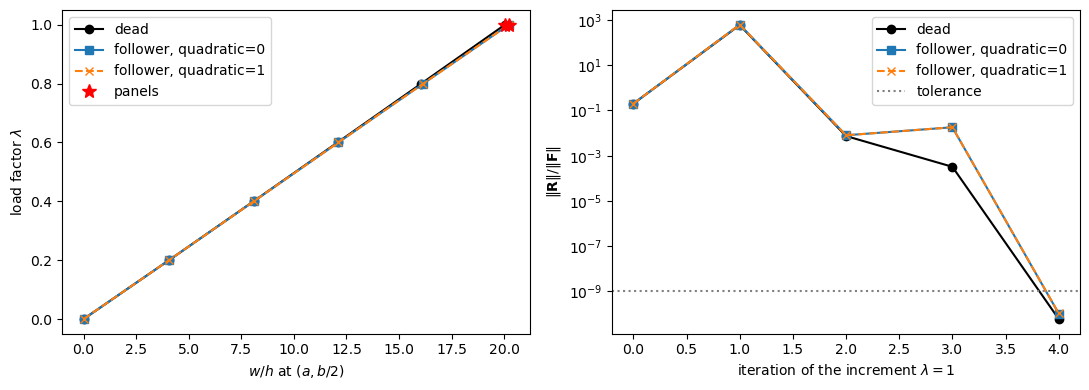

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
styles = {'dead': 'k-o', 0: 'C0-s', 1: 'C1--x'}
for load in LOADS:
    lbd, w, _ = np.array(paths[load]).T
    axes[0].plot(w, lbd, styles[load], label=NAMES[load])
    axes[1].semilogy(histories[load][-1], styles[load], label=NAMES[load])
    print('%-22s last increment: %s' % (NAMES[load], ', '.join(
          '%.2e' % e for e in histories[load][-1])))
axes[0].plot([PANELS[k]['w'] for k in ('dead', 0)], [1, 1], 'r*', ms=10,
             label='panels')
axes[0].set_xlabel('$w/h$ at $(a, b/2)$')
axes[0].set_ylabel(r'load factor $\lambda$')
axes[0].legend()
axes[1].axhline(tol, color='gray', ls=':', label='tolerance')
axes[1].set_xlabel(r'iteration of the increment $\lambda = 1$')
axes[1].set_ylabel(r'$\|\mathbf{R}\| / \|\mathbf{F}\|$')
axes[1].legend()
plt.tight_layout()
plt.show()

For the three loads the tip deflection and the tip displacement $u$ are
$4.7 \times 10^{-4}$ to $4.8 \times 10^{-4}$ and
$8.5 \times 10^{-4}$ to $8.7 \times 10^{-4}$ below the reference values of
panels, the mesh converging from below. The follower pressure increases
$w$ by 0.923 % and $|u|$ by 1.91 % over the dead pressure, within
$9 \times 10^{-4}$ of the follower effect of the reference values. The two
truncations of the area vector differ by $2 \times 10^{-8}$ in $w$, as the
consistent truncation predicts for the moderate rotations of the von Kármán
strains. Newton-Raphson needs 4 or 5 corrections per increment, also with
the unsymmetric load stiffness matrix.

## Tangent stiffness matrix against finite differences

On a mesh of 3 by 2 nodes of the laminate, under 100 times the non-uniform
pressure `p_function`, at a random state with deflections well above the
thickness, the tangent stiffness matrix
$\boldsymbol{K}_T = \boldsymbol{K}_{C0} + \boldsymbol{K}_{CNL} +
\boldsymbol{K}_{GNL} + \boldsymbol{K}_G + \boldsymbol{K}_F$ is compared,
every entry, with the central differences $\boldsymbol{J}$ of the residual
$\boldsymbol{R} = \boldsymbol{F}_{int} - \boldsymbol{F}_p$. The step of each
degree of freedom is $10^{-4}$ times its value, large enough to stay clear
of the round-off of $\boldsymbol{F}_{int}$, whose stiffness is about 500
times that of the load here. The difference is also measured against
$\boldsymbol{K}_F$ alone, to show that the load stiffness itself is
verified:

In [8]:
mt = Mesh(nx=3, ny=2)
funct = lambda x, y: 100*p_function(x, y)
rng = np.random.default_rng(7)
ut = mt.random_state(rng)
d = mt.random_state(rng)
steps = np.array([1.e-2, 1.e-3, 1.e-4, 1.e-5])
taylor = {}
print('%-14s %16s %16s %16s' % ('', '|KT - J|/|J|', '|KT - J|/|KF|',
                                '|KF|/|KT|'))
for quadratic in TRUNCATIONS:
    R = lambda u: mt.fint(u) - mt.fext_follower(u, funct, quadratic)
    Kf = mt.KCfollower(ut, funct, quadratic).toarray()
    KT = mt.KT(ut).toarray() + Kf
    J = np.empty((mt.N, mt.N))
    scale = np.abs(ut).copy()
    scale[scale == 0] = 1.
    for j in range(mt.N):
        e = np.zeros(mt.N)
        e[j] = 1.e-4*scale[j]
        J[:, j] = (R(ut + e) - R(ut - e))/(2*e[j])
    print('quadratic=%d   %16.3e %16.3e %16.3e' % (quadratic,
          np.linalg.norm(KT - J)/np.linalg.norm(J),
          np.linalg.norm(KT - J)/np.linalg.norm(Kf),
          np.linalg.norm(Kf)/np.linalg.norm(KT)))
    # Taylor test along the direction d, with and without K_F
    R0 = R(ut)
    for name, K in (('', KT), (' without K_F', KT - Kf)):
        Kd = K @ d
        taylor['quadratic=%d%s' % (quadratic, name)] = [
            np.linalg.norm(R(ut + s*d) - R0 - s*Kd)/np.linalg.norm(s*Kd)
            for s in steps]

                   |KT - J|/|J|    |KT - J|/|KF|        |KF|/|KT|
quadratic=0          8.521e-10        3.727e-07        2.286e-03
quadratic=1          8.187e-10        3.571e-07        2.292e-03


The Taylor test measures, along a random direction $\boldsymbol{d}$, the
remainder

$$
\varepsilon(s) = \frac{\| \boldsymbol{R}(\boldsymbol{u} + s \boldsymbol{d})
- \boldsymbol{R}(\boldsymbol{u}) - s \boldsymbol{K}_T \boldsymbol{d} \|}
{\| s \boldsymbol{K}_T \boldsymbol{d} \|}
$$

which falls proportionally to the step $s$ when $\boldsymbol{K}_T$ is the
Jacobian of $\boldsymbol{R}$. Leaving $\boldsymbol{K}_F$ out of the tangent
makes the remainder stall at the relative size of the missing term:

s                                  1e-02       1e-03       1e-04       1e-05
quadratic=0                    5.599e-03   5.600e-04   5.600e-05   5.600e-06
quadratic=0 without K_F        1.957e-02   1.818e-02   1.812e-02   1.811e-02
quadratic=1                    5.599e-03   5.600e-04   5.600e-05   5.600e-06
quadratic=1 without K_F        1.952e-02   1.815e-02   1.809e-02   1.808e-02


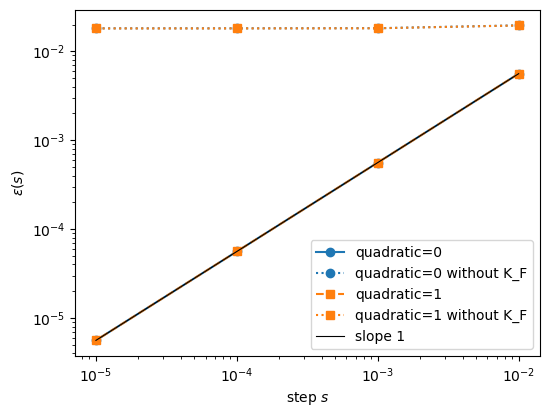

In [9]:
print('%-28s' % 's' + ''.join('%12.0e' % s for s in steps))
for name, errors in taylor.items():
    print('%-28s' % name + ''.join('%12.3e' % e for e in errors))

plt.figure(figsize=(6, 4.5))
for (name, errors), style in zip(taylor.items(), ['C0-o', 'C0:o', 'C1--s',
                                                  'C1:s']):
    plt.loglog(steps, errors, style, label=name)
plt.loglog(steps, steps*taylor['quadratic=0'][0]/steps[0], 'k-', lw=0.8,
           label='slope 1')
plt.xlabel('step $s$')
plt.ylabel(r'$\varepsilon(s)$')
plt.legend()
plt.show()

The tangent stiffness matrix differs from the central differences by
$8.5 \times 10^{-10}$ (`quadratic=0`) and $8.2 \times 10^{-10}$
(`quadratic=1`) of their norm, and by $3.7 \times 10^{-7}$ and
$3.6 \times 10^{-7}$ of the norm of $\boldsymbol{K}_F$, which is 0.23 % of
$\boldsymbol{K}_T$ here: the load stiffness matrix itself is the derivative
of the force vector. The Taylor remainder falls from
$5.6 \times 10^{-3}$ to $5.6 \times 10^{-6}$, a factor of 10 per decade of
the step, for both truncations; without $\boldsymbol{K}_F$ it stalls at
$1.8 \times 10^{-2}$.

## Symmetry of the load stiffness matrix

A load derived from a potential has a symmetric load stiffness matrix. For
the first-order area vector, $\boldsymbol{\delta}^\top \boldsymbol{K}_F
\boldsymbol{\Delta} = -P(\delta, \Delta)$ for two displacement fields
$\delta$ and $\Delta$, with $P(\delta, \Delta) = \int_A p \,
\delta\boldsymbol{u} \cdot \boldsymbol{a}_1(\Delta\boldsymbol{u}) \, dA$,
and an integration by parts gives its skew part

$$
P(\delta, \Delta) - P(\Delta, \delta) =
- \oint p \left[ (\delta u \, \Delta w - \delta w \, \Delta u) n_x
+ (\delta v \, \Delta w - \delta w \, \Delta v) n_y \right] ds
+ \int_A \left[ p_{,x} (\delta u \, \Delta w - \delta w \, \Delta u)
+ p_{,y} (\delta v \, \Delta w - \delta w \, \Delta v) \right] dA
$$

with $\{n_x, n_y\}$ the outward normal of the boundary of the loaded region.
The matrix is symmetric if and only if $p$ is uniform over the loaded region
and, at each point of its boundary, either $w = 0$ or the in-plane
displacement normal to the boundary vanishes [1, 2]. A single element is
unsymmetric, since its edges are part of the boundary of its loaded region;
in the assembled matrix the contour integrals of the interior edges cancel.
For the complete area vector away from $\boldsymbol{u} = \boldsymbol{0}$,
with $w = 0$ on the whole boundary and a uniform $p$, the load has the
potential $-p V$,

$$
V = \int_A w \left( (1 + u_{,x}) (1 + v_{,y}) - u_{,y} v_{,x} \right) dA
$$

hence a symmetric load stiffness matrix also at
$\boldsymbol{u} \neq \boldsymbol{0}$; a free edge makes it unsymmetric.

The asymmetry measure over the unknown degrees of freedom, for a mesh of 5
by 4 nodes of the laminate and the cases of `tests/test_follower_pressure.py`
(`ss`: $w = 0$ on all edges; `normal`: the normal in-plane displacement zero
on all edges; `mixed`: one or the other edge by edge; `free x = a`: $w = 0$
on three edges):

In [10]:
ms = Mesh(nx=5, ny=4)
u0 = np.zeros(ms.N)
uniform = lambda x, y: -1.e4 + 0*x*y
patch = lambda x, y: np.where(x < ms.a/2, -1.e4, 0.) + 0*y
ss = {'x1': 'w', 'x2': 'w', 'y1': 'w', 'y2': 'w'}
normal = {'x1': 'u', 'x2': 'u', 'y1': 'v', 'y2': 'v'}
mixed = {'x1': 'w', 'x2': 'u', 'y1': 'v', 'y2': 'w'}
free = {'x1': 'w', 'y1': 'w', 'y2': 'w'}

# complete area vector at a state with w = 0 on the boundary
rng = np.random.default_rng(2)
us = ms.random_state(rng)
us[boundary_flags(ms, ss)] = 0
Kq = ms.KCfollower(us, uniform, 1)
Kq0 = ms.KCfollower(u0, uniform, 1)
print('complete area vector, |K_F(u) - K_F(0)|/|K_F(0)| = %.3e'
      % (np.linalg.norm((Kq - Kq0).toarray())/np.linalg.norm(Kq0.toarray())))
print()

single = Mesh(nx=2, ny=2)
cases = [
    ('single element, all dofs free', 'uniform', 0, 'no',
     asym(single.KCfollower(np.zeros(single.N), uniform, 0))),
]
for label, edges, f, fname, quadratic, u, expected in [
        ('ss', ss, uniform, 'uniform', 0, u0, 'yes'),
        ('normal', normal, uniform, 'uniform', 0, u0, 'yes'),
        ('mixed', mixed, uniform, 'uniform', 0, u0, 'yes'),
        ('free x = a', free, uniform, 'uniform', 0, u0, 'no'),
        ('ss', ss, p_function, 'p_function', 0, u0, 'no'),
        ('ss', ss, patch, 'x < a/2 only', 0, u0, 'no'),
        ('ss, u != 0', ss, uniform, 'uniform', 1, us, 'yes'),
        ('free x = a, u != 0', free, uniform, 'uniform', 1, us, 'no')]:
    bu_s = ~boundary_flags(ms, edges)
    K = ms.KCfollower(u, f, quadratic)
    cases.append((label, fname, quadratic, expected, asym(K[bu_s, :][:, bu_s])))

print('%-30s %-14s %9s %10s %12s' % ('boundary conditions', 'pressure',
      'quadratic', 'symmetric', 'asymmetry'))
for label, fname, quadratic, expected, value in cases:
    print('%-30s %-14s %9d %10s %12.3e' % (label, fname, quadratic, expected,
                                         value))

complete area vector, |K_F(u) - K_F(0)|/|K_F(0)| = 6.007e-02

boundary conditions            pressure       quadratic  symmetric    asymmetry
single element, all dofs free  uniform                0         no    1.411e+00
ss                             uniform                0        yes    1.759e-16
normal                         uniform                0        yes    1.807e-16
mixed                          uniform                0        yes    1.791e-16
free x = a                     uniform                0         no    4.956e-01
ss                             p_function             0         no    5.619e-01
ss                             x < a/2 only           0         no    7.449e-01
ss, u != 0                     uniform                1        yes    3.565e-16
free x = a, u != 0             uniform                1         no    4.963e-01


With a uniform pressure and, on every edge, $w = 0$ or the normal in-plane
displacement zero, the asymmetry is at the round-off level, below
$4 \times 10^{-16}$, also for the complete area vector at a deformed state
where $\boldsymbol{K}_F$ differs by 6.0 % from that of the undeformed
state. A single element, a free edge, a varying pressure and a pressure on
part of the plate give an unsymmetric matrix, with an asymmetry between
0.50 and 1.41.

## References

1. Hibbitt, H. D., Some follower forces and load stiffness, *International Journal for Numerical Methods in Engineering*, 14(6), 937-941, 1979, doi:10.1002/nme.1620140613.
2. Schweizerhof, K., and Ramm, E., Displacement dependent pressure loads in nonlinear finite element analyses, *Computers & Structures*, 18(6), 1099-1114, 1984, doi:10.1016/0045-7949(84)90154-8.
3. Castro, S. G. P., and Donadon, M. V., Assembly of semi-analytical models to address linear buckling and vibration of stiffened composite panels with debonding defect, *Composite Structures*, 160, 232-247, 2017, doi:10.1016/j.compstruct.2016.10.026.